# Lab 6 — Diagnose It Yourself

Five datasets, `a` through `e`. Four of them were made by exactly one of the mechanisms from
Lecture 13 Part 2 — a **mixture** of two populations, **correlated** samples, a **heavy
tail**, or a **product** instead of a sum. One is a plain, ordinary normal sample with
nothing wrong with it.

Your job: say which is which, **including which one is fine**, and name the panel that gave
each one away. The generating code is deliberately not here.

Two things to know before you start:

* Each dataset comes with a `group` covariate, a 0/1 label. For all but one of them it is
  pure noise. Splitting by it is therefore a real diagnostic and not a giveaway.
* **Row order is meaningful. Do not sort or shuffle.** Two of the six panels read the order
  of the rows, and sorting destroys the evidence they look for.


The setup below is the toolkit from Lecture 13. The only change is one optional argument on `diagnose` (`log_panel`), used in Part 1. Read it if you want to, but you do not need to modify any of it — everything you need is in `diagnose`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
%matplotlib inline

In [2]:
def hist_with_normal(x, bins=50, ax=None, label=None):
    if ax is None:
        ax = plt.gca()
    x = np.asarray(x)
    _, edges, _ = ax.hist(x, bins=bins, density=True, alpha=0.6, label=label)
    grid = np.linspace(edges[0], edges[-1], 300)
    ax.plot(grid, stats.norm.pdf(grid, np.mean(x), np.std(x)), "k--", label="normal, same mean & std")
    ax.legend(fontsize=8)

In [3]:
def qq_plot(x, ax=None, label=None):
    if ax is None:
        ax = plt.gca()
    x = np.sort(np.asarray(x))
    n = len(x)
    theoretical = stats.norm.ppf((np.arange(1, n + 1) - 0.5) / n)
    ax.scatter(theoretical, x, s=4, label=label)

    q25, q50, q75 = np.percentile(x, [25, 50, 75])
    slope = (q75 - q25) / (stats.norm.ppf(0.75) - stats.norm.ppf(0.25))
    ax.plot(theoretical, q50 + slope * theoretical, "k--", lw=1)
    ax.set_xlabel("normal quantile")
    ax.set_ylabel("data quantile")

In [4]:
def running_mean(x):
    x = np.asarray(x)
    return np.cumsum(x) / np.arange(1, len(x) + 1)

In [5]:
def autocorrelation(x, max_lag):
    x = np.asarray(x) - np.mean(x)
    denominator = np.sum(x * x)
    result = list()
    for lag in range(max_lag + 1):
        result.append(np.sum(x[:len(x) - lag] * x[lag:]) / denominator)
    return result

In [6]:
def diagnose(x, group=None, name="", log_panel=True):
    x = np.asarray(x)
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    fig.suptitle(name)

    hist_with_normal(x, ax=axes[0, 0])
    axes[0, 0].set_title("histogram vs normal")

    qq_plot(x, ax=axes[0, 1])
    axes[0, 1].set_title("Q-Q plot")

    if log_panel and np.all(x > 0):
        hist_with_normal(np.log(x), ax=axes[0, 2])
        axes[0, 2].set_title("histogram of log(x)")
    elif not log_panel:
        axes[0, 2].set_title("log panel off (data already transformed)")
    else:
        axes[0, 2].set_title("log: not possible (values <= 0)")

    axes[1, 0].plot(running_mean(x))
    axes[1, 0].set_title("running mean")

    axes[1, 1].plot(autocorrelation(x, 50), marker=".")
    axes[1, 1].axhline(0, color="k", lw=0.5)
    axes[1, 1].set_title("autocorrelation")

    if group is not None:
        bins = np.histogram_bin_edges(x, bins=40)
        axes[1, 2].hist(x[group == 0], bins=bins, alpha=0.5, density=True, label="group 0")
        axes[1, 2].hist(x[group == 1], bins=bins, alpha=0.5, density=True, label="group 1")
        axes[1, 2].legend()
    axes[1, 2].set_title("split by covariate")

    plt.tight_layout()
    plt.show()

Load the five datasets. Each name `x` has a partner `x_group` holding its covariate.

In [7]:
mystery = np.load("Lab.6.mystery.npz")
for name in ["a", "b", "c", "d", "e"]:
    print(name, mystery[name].shape)

a (1500,)
b (1500,)
c (1500,)
d (1500,)
e (1500,)


`diagnose` takes the data, its covariate, and a title. Here is the call for `a`; the reading of it is yours.

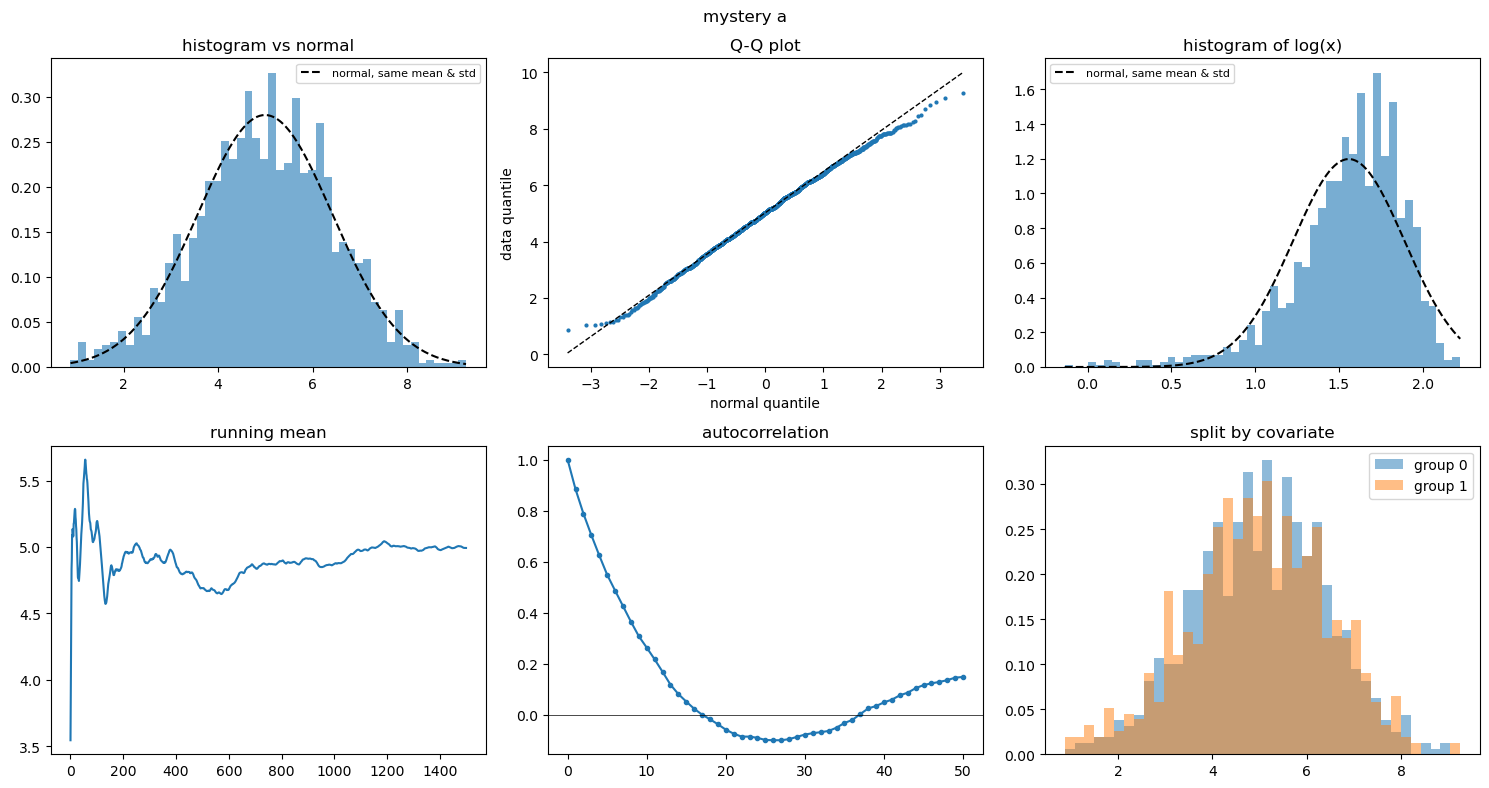

In [8]:
diagnose(mystery["a"], mystery["a_group"], "mystery a")

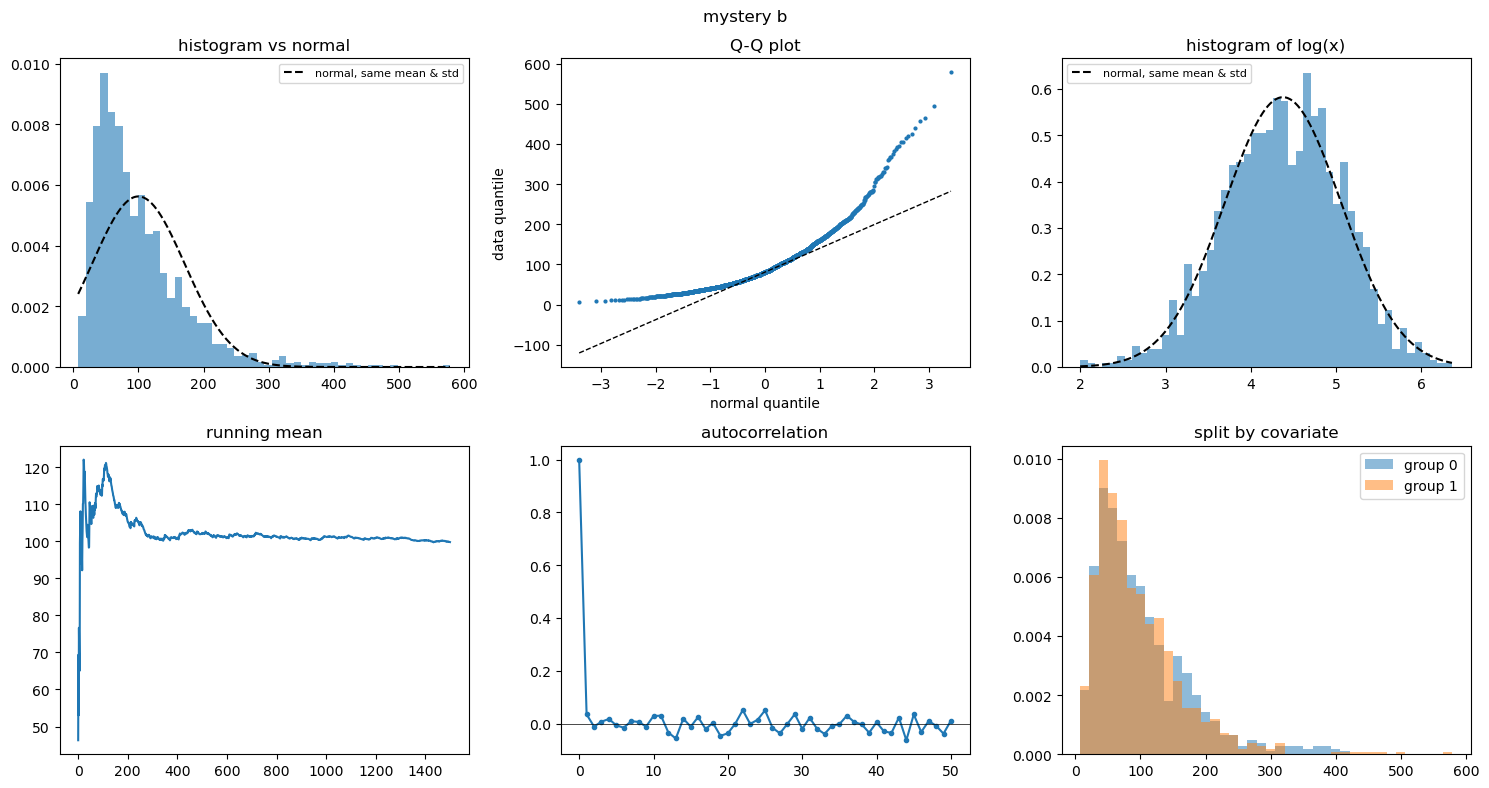

In [9]:
diagnose(mystery["b"], mystery["b_group"], "mystery b")

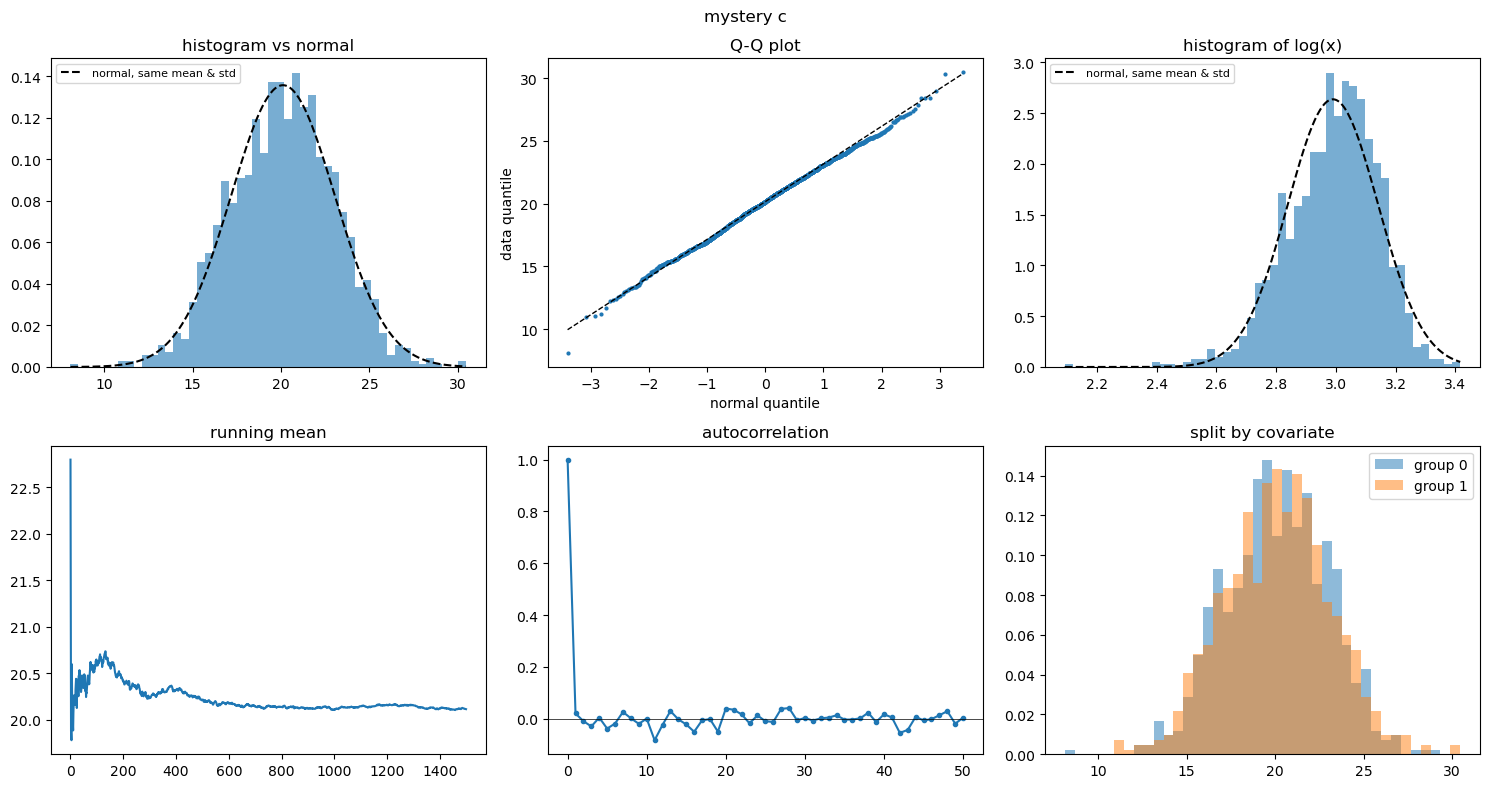

In [10]:
diagnose(mystery["c"], mystery["c_group"], "mystery c")

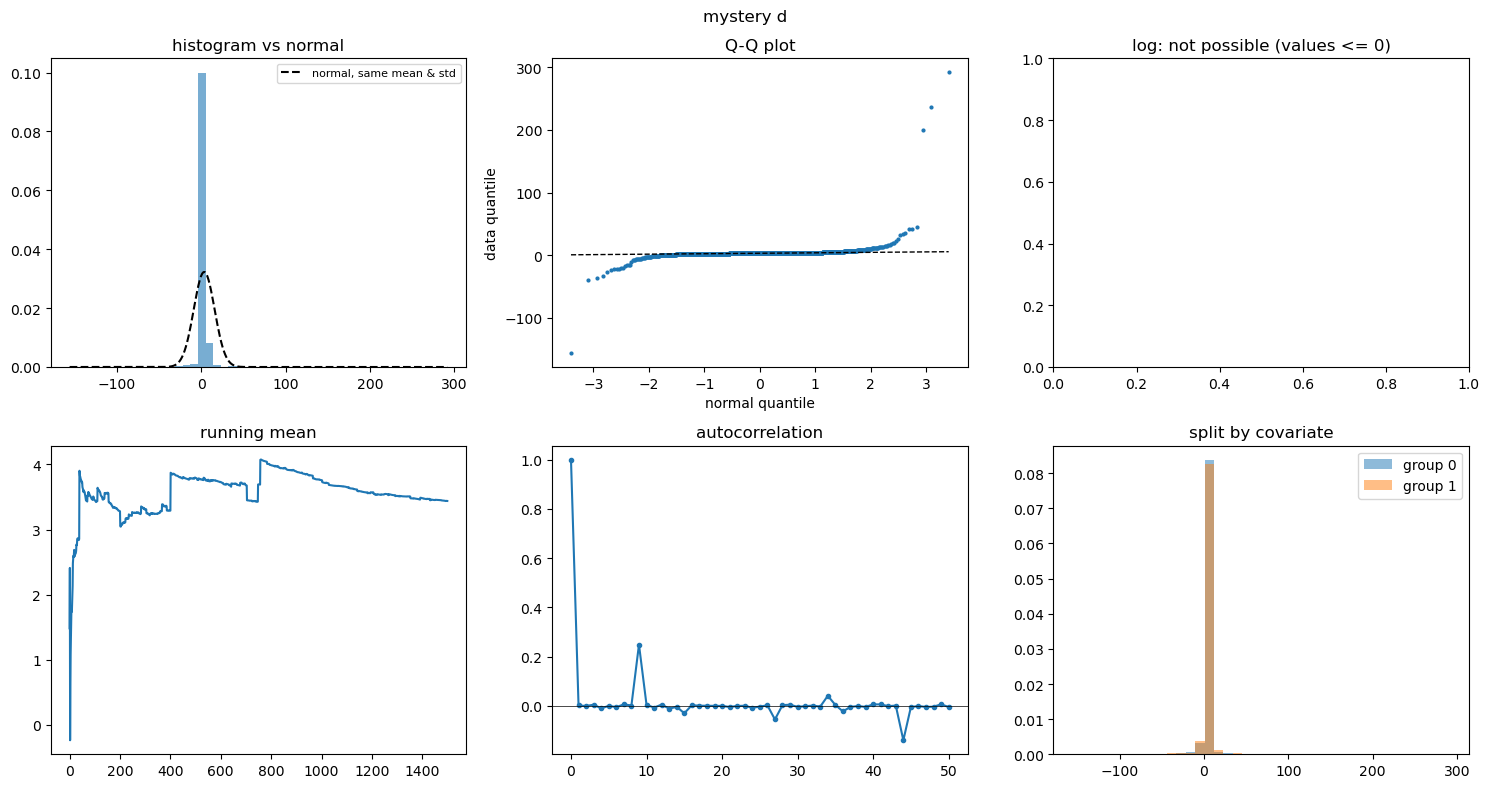

In [11]:
diagnose(mystery["d"], mystery["d_group"], "mystery d")

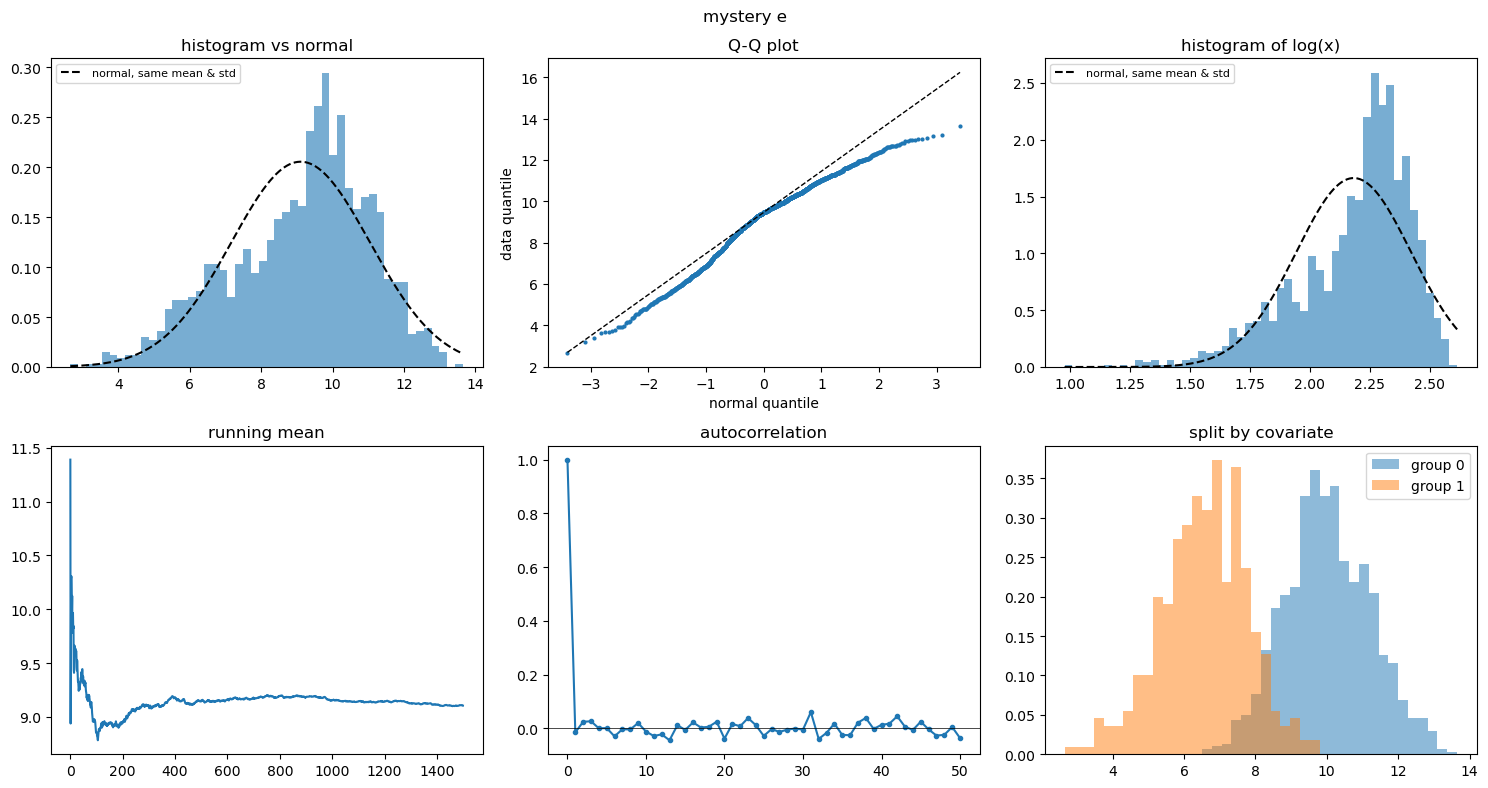

In [12]:
diagnose(mystery["e"], mystery["e_group"], "mystery e")

## What to hand in

Fill in the table, in this notebook. One line of reasoning per dataset is enough — what
matters is that the panel you name is the one that actually shows the problem.

| Dataset | Which assumption broke (or none) | Which panel told you | What you would do next with real data of this kind |
|---|---|---|---|
| `a` | **Correlated samples** (independence broke. positive serial correlation across consecutive rows while the marginal shape stays normal) | **Autocorrelation** (and **running mean**, which wanders slowly instead of settling) | Account for serial dependence using block bootstrap, Newey–West / HAC standard errors, or an autoregressive time-series model rather than naive independent-sample SEs. |
| `b` | **Product instead of a sum** (multiplicative / log-normal process producing strong right skew) | **Histogram of `log(x)`** (which becomes symmetric and bell-shaped, alongside the upward-curving **Q-Q plot** and right-skewed **histogram**) | Work on the `log(x)` scale for normal-theory modeling and inference, or summarize using geometric mean / median and multiplicative intervals. |
| `c` | **None** (plain normal sample; no broken assumptions) | **All six panels** (histogram and Q-Q plot hug the normal reference, running mean settles smoothly, autocorrelation is ~0, and groups 0 and 1 overlap) | Proceed with standard parametric summaries (sample mean and standard error) without unnecessary transformations. |
| `d` | **Heavy tail** (extreme outliers far outside normal tail expectations) | **Q-Q plot** (tails peel sharply away from the diagonal line at both ends; also visible as jumps in the **running mean** and wide spikes in the **histogram**) | Inspect extreme observations for data errors vs. genuine tail events, and use robust estimators (median, IQR, trimmed mean) or heavy-tailed distributions (e.g., Student-$t$). |
| `e` | **Mixture of two populations** (unimodal-looking but left-skewed combined distribution formed by two distinct subgroups) | **Split by covariate** (shows two distinct normal distributions: group 0 centered near 10.02 and group 1 centered near 6.58) | Stratify the analysis by the group covariate (or include `group` in the model) and report separate summaries for each subpopulation rather than pooling them. |

Two warnings, from the people who did this before you:

* One of the five passes every test of **shape** — its histogram and its Q–Q plot look
  perfectly normal. If you only look at the top row of panels, you will call it clean.
* Not every non-normal histogram is a broken assumption, and exactly one dataset here is
  fine. Resist diagnosing it anyway.


## Test your diagnosis

Diagnosing a problem is only the first step. Now test whether the action you proposed actually helps. There are three short checks.

**Do not change your original diagnosis table.** These are follow-up checks.


### 1. Test a transformation

Which dataset do you think came from a multiplicative/product process?

Enter its letter below, apply a log transformation, and run the diagnostics again.

Compare the transformed result with the original, especially the **histogram** and **Q-Q plot**.

In 2–3 sentences, answer:

- Did the transformation make the data look more compatible with a normal model?
- What changed?


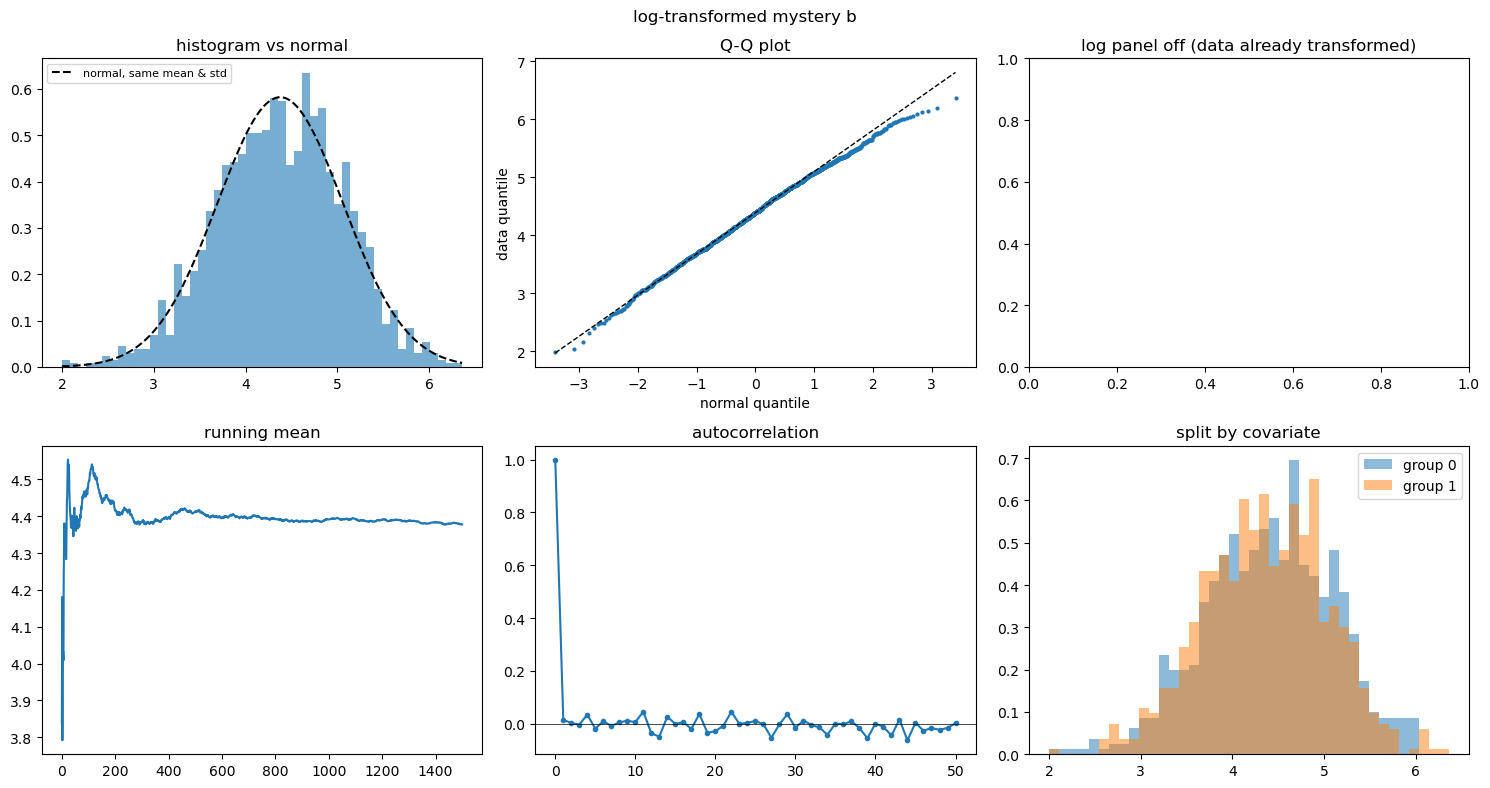

In [13]:
product_name = "b"   # enter a, b, c, d, or e

if product_name not in ["a", "b", "c", "d", "e"]:
    print("Enter one dataset letter: a, b, c, d, or e.")
else:
    x = mystery[product_name]
    g = mystery[product_name + "_group"]

    if np.all(x > 0):
        x_log = np.log(x)
        diagnose(
            x_log,
            g,
            "log-transformed mystery " + product_name,
            log_panel=False
        )
    else:
        print(
            "This dataset contains non-positive values, so log(x) is not "
            "defined for every observation. Revisit your diagnosis."
        )


**What changed after the transformation?**

Your answer:

*Applying log(x) made dataset "b" look completely compatible with a normal model (skewness dropped from 1.87 to -0.16 and excess kurtosis dropped from 5.26 to -0.10). In the original plot, the histogram was heavily rightskewed with a long upper tail and the Q-Q plot curved sharply upward. After taking the log, the histogram is symmetric and closely hugs the dashed normal density curve, while the Q-Q plot points fall straight along the diagonal reference line.*


### 2. Test the possible mixture

Which dataset do you think contains a mixture of two populations?

Choose that dataset below and examine **group 0** and **group 1** separately.

Compare:

- their means and standard deviations,
- their distributions,
- whether each group looks simpler than the combined sample.

**Note:** the running-mean and autocorrelation panels are not meaningful on a single group, because dropping rows breaks the row order. Look at the histogram and Q-Q plot here.


In [14]:
mixture_name = "e"   # enter a, b, c, d, or e

if mixture_name not in ["a", "b", "c", "d", "e"]:
    print("Enter one dataset letter: a, b, c, d, or e.")
else:
    x = mystery[mixture_name]
    g = mystery[mixture_name + "_group"]

    x0 = x[g == 0]
    x1 = x[g == 1]

    print(
        "group 0:",
        "n =", len(x0),
        "mean =", np.mean(x0),
        "std =", np.std(x0)
    )

    print(
        "group 1:",
        "n =", len(x1),
        "mean =", np.mean(x1),
        "std =", np.std(x1)
    )


group 0: n = 1100 mean = 10.023609483068928 std = 1.2076160077192382
group 1: n = 400 mean = 6.5783802616725096 std = 1.1958270534509683


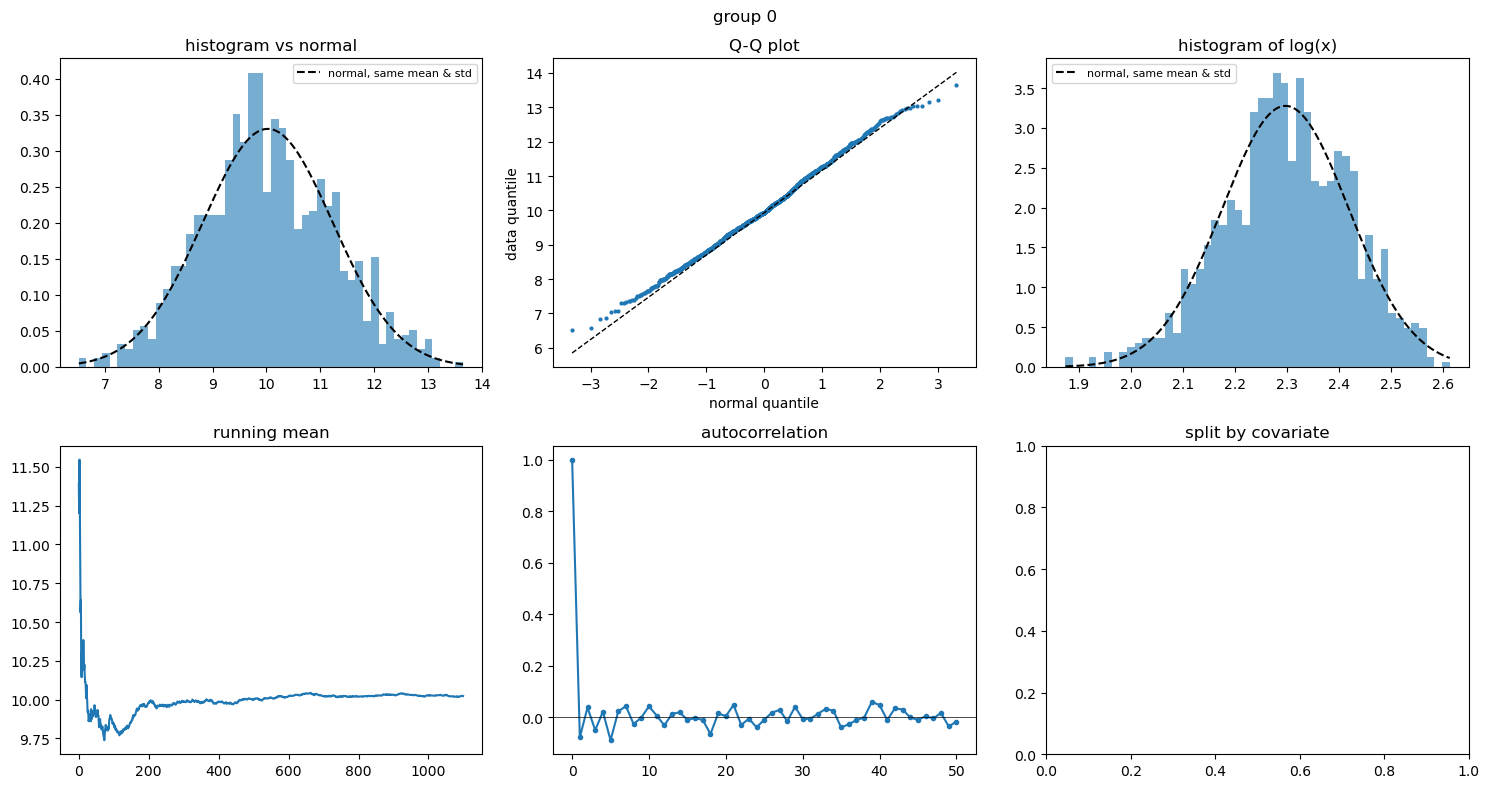

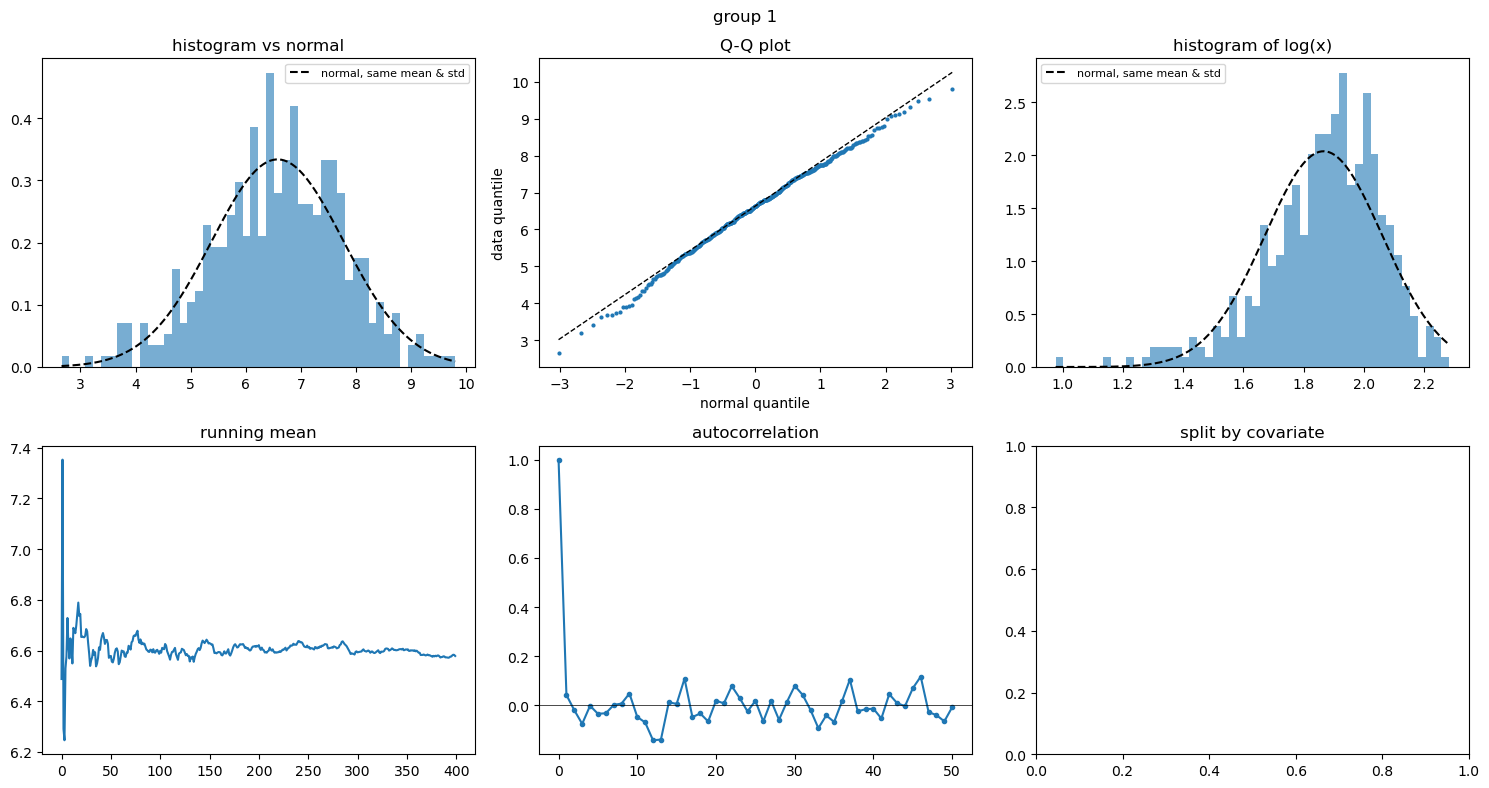

In [15]:
if mixture_name in ["a", "b", "c", "d", "e"]:
    diagnose(x0, name="group 0")
    diagnose(x1, name="group 1")


**After separating the groups, does your mixture diagnosis look more convincing? Why?**

Your answer:

*Yes, separating the groups makes the mixture diagnosis unmistakable. While the dataset "e" had a broad leftskewed distribution (mean = 9.10, std = 1.94, skew = -0.50) with a shoulder, splitting by group reveals two clean, symmetric normal populations with almost identical spread (std = 1.21 for group 0 vs. 1.20 for group 1) but very different means (10.02 with n = 1100 for group 0 vs. 6.58 with n = 400 for group 1). In their individual diagnostic plots, both group 0 and group 1 closely hug the normal curve on the histogram and follow the straight reference line on the Q-Q plot.*


### 3. Diagnosis vs. treatment

Naming a problem is not the same as fixing it. For two of the datasets, test whether the treatment you would choose actually changes the answer.

We care about one number: the **mean** of the dataset, and how precisely we know it. The **standard error (SE)** is the uncertainty on that number — smaller means more precise. The helper below estimates an SE by bootstrap: resample the data many times, recompute the statistic each time, and take the spread.

* `block=1` resamples single rows (fine when rows are independent).
* `block=50` resamples chunks of 50 consecutive rows, so neighbouring rows stay together and any dependence between them is kept.

In [16]:
def bootstrap_se(x, stat=np.mean, block=1, n_boot=2000, seed=0):
    """Bootstrap standard error of stat(x). block > 1 resamples chunks of consecutive rows."""
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    n = len(x)
    n_blocks = int(np.ceil(n / block))
    starts = rng.integers(0, n_blocks, (n_boot, n_blocks)) * block
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n]
    samples = x[np.minimum(idx, n - 1)]
    return np.std(stat(samples, axis=1))

**3a. The correlated dataset.** Enter its letter. Compare the naive SE (which assumes independent rows) with the block-bootstrap SE (which does not).

In [17]:
corr_name = "a"   # enter a, b, c, d, or e

if corr_name not in ["a", "b", "c", "d", "e"]:
    print("Enter one dataset letter: a, b, c, d, or e.")
else:
    x = mystery[corr_name]
    print("mean:                          ", np.mean(x))
    print("naive SE (assumes independent):", np.std(x, ddof=1) / np.sqrt(len(x)))
    print("block-bootstrap SE (block=50): ", bootstrap_se(x, np.mean, block=50))

mean:                           4.992392627391782
naive SE (assumes independent): 0.03684092171356295
block-bootstrap SE (block=50):  0.11576018347718767


**Your answer (2 sentences):** Which SE would you report, and what does the gap between the two tell you about how much data you really have?

Your answer:

*I would report the block bootstrap SE (0.116) rather than the naive SE (0.037), because strong positive autocorrelation between consecutive observations violates the independence assumption and makes the naive formula severely underestimate the uncertainty. Since the block bootstrap SE is roughly 3.14 times larger, our 1,500 correlated rows provide only as much independent information about the mean as roughly 150 truly independent observations.*


**3b. The heavy-tailed dataset.** Enter its letter. Compare the mean with the median, and how precisely each one is estimated.

In [18]:
tail_name = "d"   # enter a, b, c, d, or e

if tail_name not in ["a", "b", "c", "d", "e"]:
    print("Enter one dataset letter: a, b, c, d, or e.")
else:
    x = mystery[tail_name]
    print("mean:   ", np.mean(x),   "  SE of mean:  ", bootstrap_se(x, np.mean))
    print("median: ", np.median(x), "  SE of median:", bootstrap_se(x, np.median))
    print("largest |value|:", np.max(np.abs(x)), "  typical spread (IQR):", np.subtract(*np.percentile(x, [75, 25])))

mean:    3.43844668155372   SE of mean:   0.3220438807205929
median:  3.0071175982514977   SE of median: 0.025847962673370552
largest |value|: 291.8860760749299   typical spread (IQR): 0.9803251839983336


**Your answer (2 sentences):** Which summary would you report, and why? What would you also do about the extreme observations before trusting either number?

Your answer:

*I would report the **median** (3.007, with SE = 0.026 and IQR = 0.980) rather than the sample mean (3.438, SE = 0.322), because a few extreme values (up to 291.89) pull the mean upward and inflate its standard error to much larger than that of the median. Before trusting either summary, I would inspect the extreme observations (-156.23 and 291.89) in context to detremine whether they are recording/sensor glitches that should be cleaned or genuine heavy tailed events that must be modeled.*


**3c. Reflection (2–3 sentences).** One of the five datasets needed no treatment at all. Which one, and what could go wrong if you "treated" it anyway (for example by logging it or switching to the median)?

Your answer:

Dataset "c" needed no treatment at all because it is already an independent, well behaved normal sample (mean = 20.11, std = 2.94, skew = -0.07, autocorrelation ~ 0). If applied log(x), it would artificially introduce left skew (skew = -0.59, kurtosis = 1.00) and change the target parameter from the arithmetic mean on the original scale to the geometric mean. Similarly, switching to the median on truly normal data throws away statistical efficiency (increasing the standard error of the location estimate by about 25%, sqrt(pi/2) ~ 1.253) without providing any benefit.
